# Integrantes:
Carlos Sandro e
Hugo Martins

---

# Importações

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [4]:
uploads = files.upload()

Saving imagem_05.png to imagem_05.png
Saving imagem_04.png to imagem_04.png
Saving imagem_03.png to imagem_03.png
Saving imagem_02.png to imagem_02.png
Saving imagem_01.png to imagem_01.png


In [7]:
img_1 = cv2.imread('imagem_01.png')
img_2 = cv2.imread('imagem_02.png')
img_3 = cv2.imread('imagem_03.png')
img_4 = cv2.imread('imagem_04.png')
img_5 = cv2.imread('imagem_05.png')

In [8]:
img_1_vetor = img_1.ravel()
img_2_vetor = img_2.ravel()
img_3_vetor = img_3.ravel()
img_4_vetor = img_4.ravel()
img_5_vetor = img_5.ravel()

In [9]:
img_1_array = np.zeros(256)
for pixel in img_1_vetor:
  img_1_array[pixel] += 1

img_2_array = np.zeros(256)
for pixel in img_2_vetor:
  img_2_array[pixel] += 1

img_3_array = np.zeros(256)
for pixel in img_3_vetor:
  img_3_array[pixel] += 1

img_4_array = np.zeros(256)
for pixel in img_4_vetor:
  img_4_array[pixel] += 1

img_5_array = np.zeros(256)
for pixel in img_5_vetor:
  img_5_array[pixel] += 1

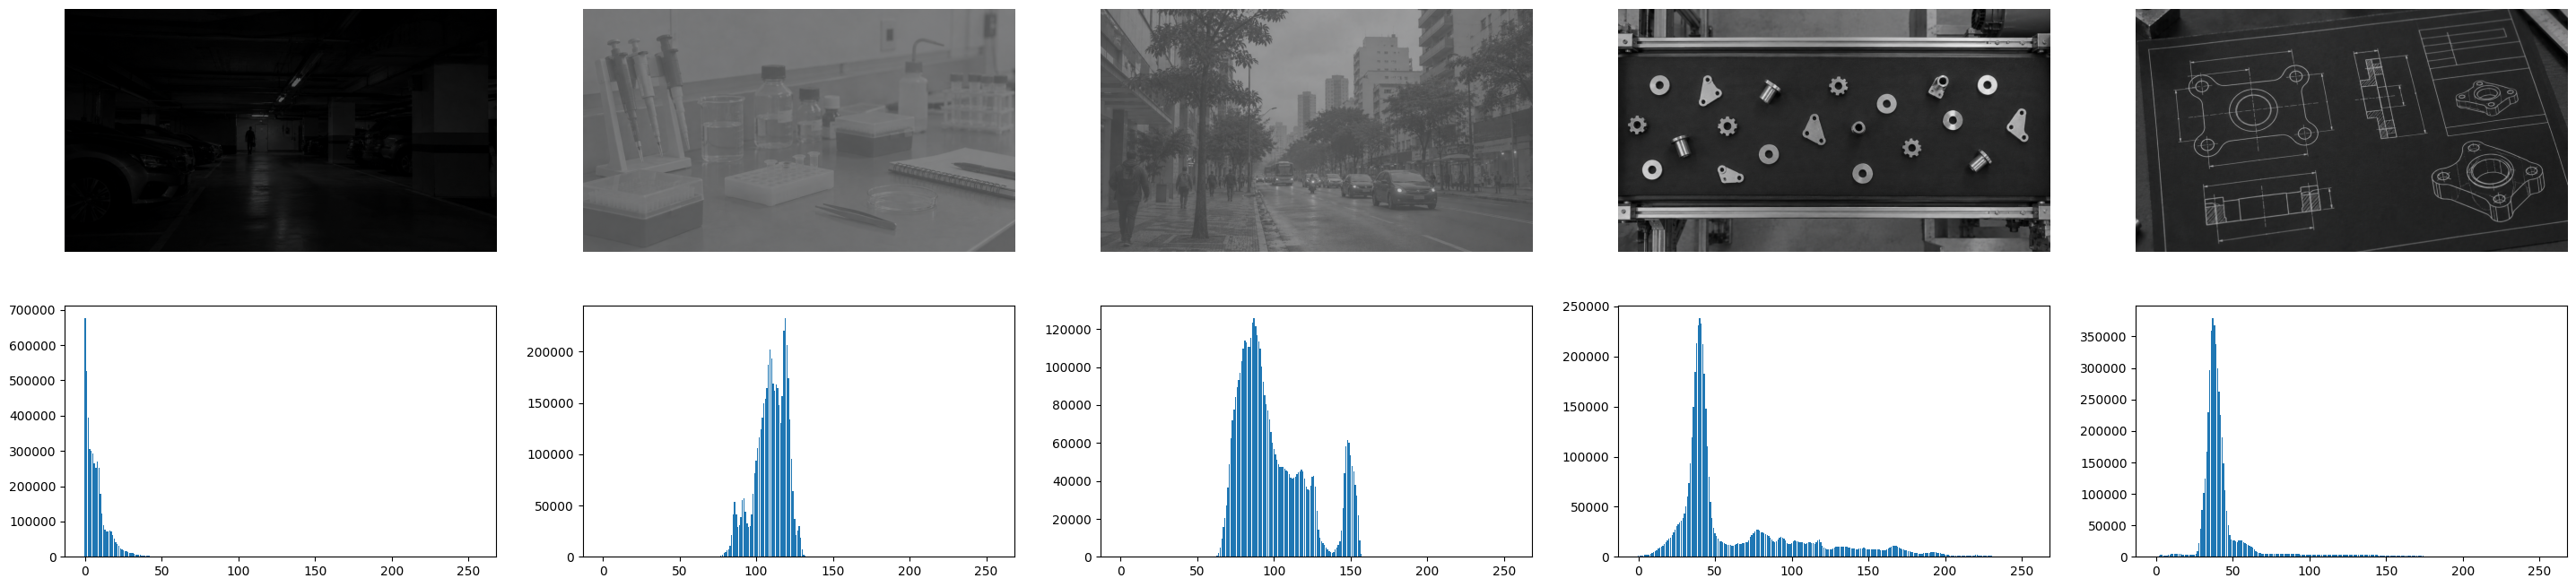

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(36, 8))

axes[0, 0].imshow(img_1, cmap='gray', vmin=0, vmax=255)
axes[0, 0].axis('off')

axes[1, 0].bar(range(256), img_1_array)

axes[0, 1].imshow(img_2, cmap='gray', vmin=0, vmax=255)
axes[0, 1].axis('off')

axes[1, 1].bar(range(256), img_2_array)

axes[0, 2].imshow(img_3, cmap='gray', vmin=0, vmax=255)
axes[0, 2].axis('off')

axes[1, 2].bar(range(256), img_3_array)

axes[0, 3].imshow(img_4, cmap='gray', vmin=0, vmax=255)
axes[0, 3].axis('off')

axes[1, 3].bar(range(256), img_4_array)

axes[0, 4].imshow(img_5, cmap='gray', vmin=0, vmax=255)
axes[0, 4].axis('off')

axes[1, 4].bar(range(256), img_5_array)

plt.savefig('imagens_originais.png', bbox_inches='tight', dpi=300)
plt.show()

# Análise e Justificativas:
## Imagem 1:
A imagem 1 é um exemplo de foto tirada em um ambiente muito escuro. Seu histograma mostra uma alta concentração de pixels nos valores baixos de intensidade. Para corrigir isso, iremos aplicar a correção de gama, técnica capaz de escurecer imagens claras e esclarecer imagens escuras, que é o nosso caso.

## Imagem 2:
A imagem 2 possui um alcance de intensidaed muito baixo, com muitos pixels concentrados somente no meio do histograma. Por possuir muitos valores nessa faixa, e o tamanho de tal faixa ser muito pequeno, vamos utilizar a equalização de histograma. Essa técnica redistribui os valores dos pixels por todo o histograma, em vez de concentrar eles, perfeito para o nosso caso.

## Imagem 3:
A imagem 3 é um caso similar à imagem 2, onde ela possui uma quantidade de pixels muito alta concentrada no meio de seu histograma. O que diferencia elas é que a imagem 3 possui uma distribuição levemente mais ampla, com quantidade de pixeis que não chegam a mesma quantidade que na imagem 2. Nesse caso, usaremos a expansão de contraste, aonde os valores são "esticados" pelo histograma, em vez de serem redistribuidos.

## Imagem 4:
A imagem 4 em sí não possui nenhum artefato especifico com ela, mas é provavel que ela esteja sendo utilizada em um caso como treinamento de uma inteligencia artificial, onde tal IA deve analisar, identificar e classificar cada peça individual na imagem. Para ajudar nesse propósito, podemos aplicar a limiarização para destacar as peças melhor do fundo.

## Imagem 5:
A imagem 5 é uma foto levemente escura, mas principalmente possui detalhes claros em um fundo escuro. Pode ser que, nesse caso, há alguns detalhes que não conseguimos perceber na foto, pois não se destacam do fundo. Para isso, podemos fazer um negativo digital dela, para ver se alguma coisa se destaca nesse negativo.



---



# Imagem 1

In [13]:
def correcao_gamma(imagem, gamma):
    if gamma <= 0:
        raise ValueError("O valor de gamma deve ser maior que zero.")

    imagem_normalizada = imagem / 255.0
    resultado = 255 * (imagem_normalizada ** gamma)

    return resultado.astype(np.uint8)

In [22]:
img_1_corrigida = correcao_gamma(img_1, 0.4)

img_1_corrigida_vetor = img_1_corrigida.ravel()

img_1_corrigida_array = np.zeros(256)
for pixel in img_1_corrigida_vetor:
  img_1_corrigida_array[pixel] += 1

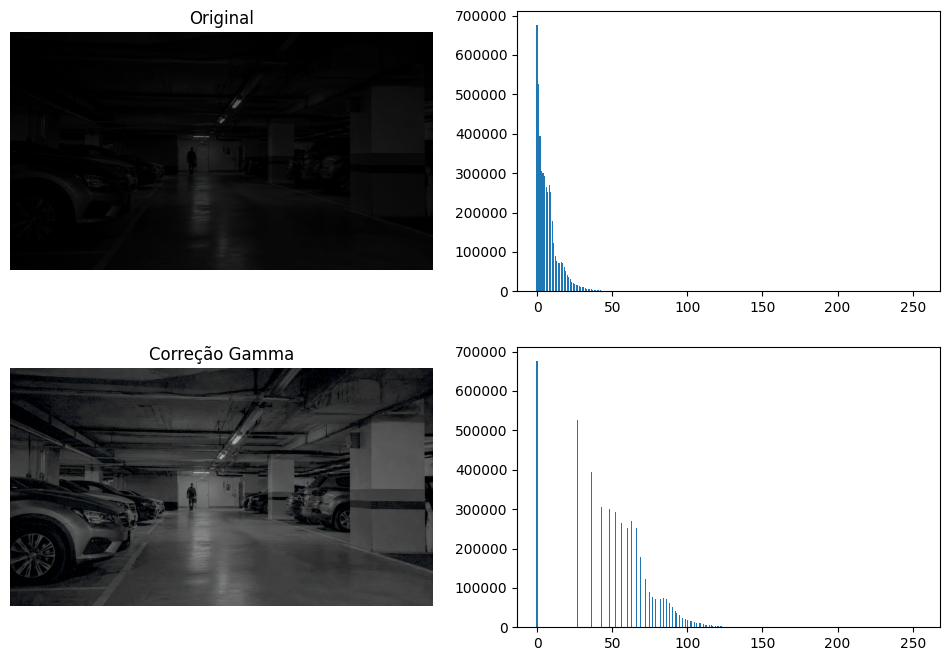

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_1, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].bar(range(256), img_1_array)

axes[1, 0].imshow(img_1_corrigida, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Correção Gamma")
axes[1, 0].axis('off')

axes[1, 1].bar(range(256), img_1_corrigida_array)

plt.savefig('imagem_1_corrigida.png', bbox_inches='tight', dpi=300)
plt.show()

# Imagem 2

In [28]:
def equalizacao_histograma(imagem):
    histograma = np.zeros(256, dtype=int)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            nivel = imagem[i, j]
            histograma[nivel] += 1

    cdf = np.cumsum(histograma)

    cdf_normalizada = 255 * cdf / cdf[-1]

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = cdf_normalizada[imagem[i, j]]

    return resultado.astype(np.uint8)

In [29]:
img_2_equalizada = equalizacao_histograma(img_2)

img_2_equalizada_vetor = img_2_equalizada.ravel()

img_2_equalizada_array = np.zeros(256)
for pixel in img_2_equalizada_vetor:
  img_2_equalizada_array[pixel] += 1

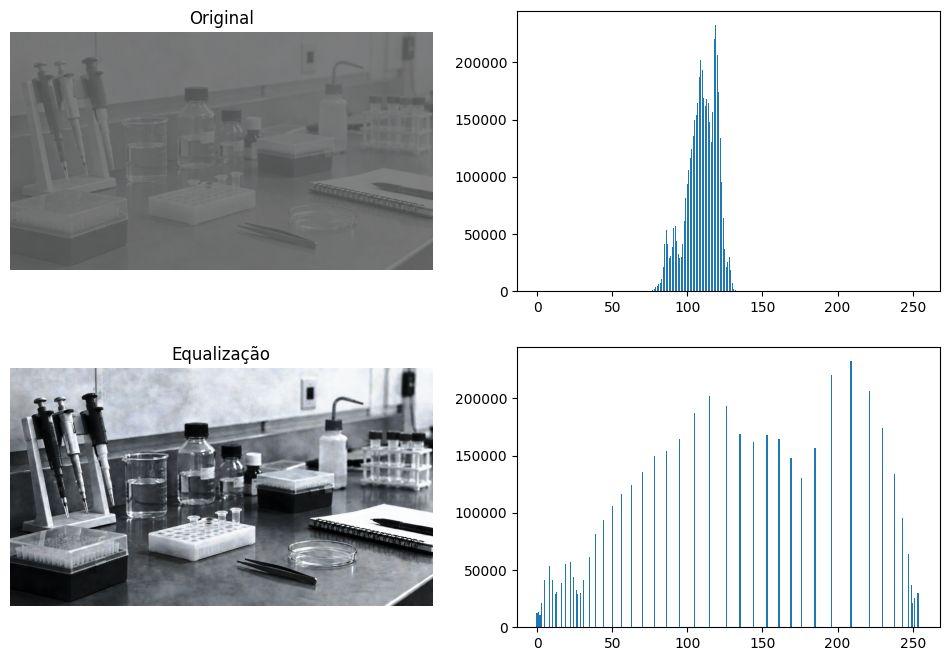

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_2, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].bar(range(256), img_2_array)

axes[1, 0].imshow(img_2_equalizada, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Equalização")
axes[1, 0].axis('off')

axes[1, 1].bar(range(256), img_2_equalizada_array)

plt.savefig('imagem_2_equalizada.png', bbox_inches='tight', dpi=300)
plt.show()

# Imagem 3

In [31]:
def expansao_contraste(imagem):
    L = imagem.min()
    H = imagem.max()

    if H == L:
        return imagem.copy()

    resultado = (imagem.astype(float) - L) * 255 / (H - L)

    return resultado.astype(np.uint8)

In [32]:
img_3_expandida = equalizacao_histograma(img_3)

img_3_expandida_vetor = img_3_expandida.ravel()

img_3_expandida_array = np.zeros(256)
for pixel in img_3_expandida_vetor:
  img_3_expandida_array[pixel] += 1

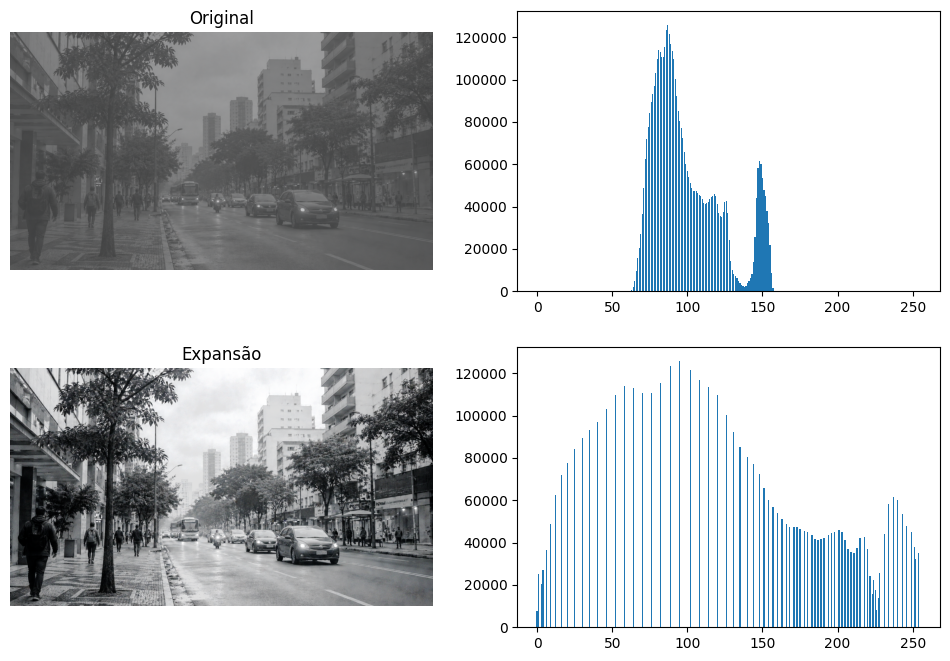

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_3, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].bar(range(256), img_3_array)

axes[1, 0].imshow(img_3_expandida, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Expansão")
axes[1, 0].axis('off')

axes[1, 1].bar(range(256), img_3_expandida_array)

plt.savefig('imagem_3_expandida.png', bbox_inches='tight', dpi=300)
plt.show()

# Imagem 4

In [36]:
def limiarizacao(imagem, limiar, tipo="superior"):
    if tipo == "superior":
        return np.where(imagem >= limiar, 255, 0).astype(np.uint8)

    elif tipo == "inferior":
        return np.where(imagem <= limiar, 255, 0).astype(np.uint8)

    else:
        raise ValueError("O tipo deve ser 'superior' ou 'inferior'.")


In [40]:
img_4_limiarizada = limiarizacao(img_4, 60)

img_4_limiarizada_vetor = img_4_limiarizada.ravel()

img_4_limiarizada_array = np.zeros(256)
for pixel in img_4_limiarizada_vetor:
  img_4_limiarizada_array[pixel] += 1

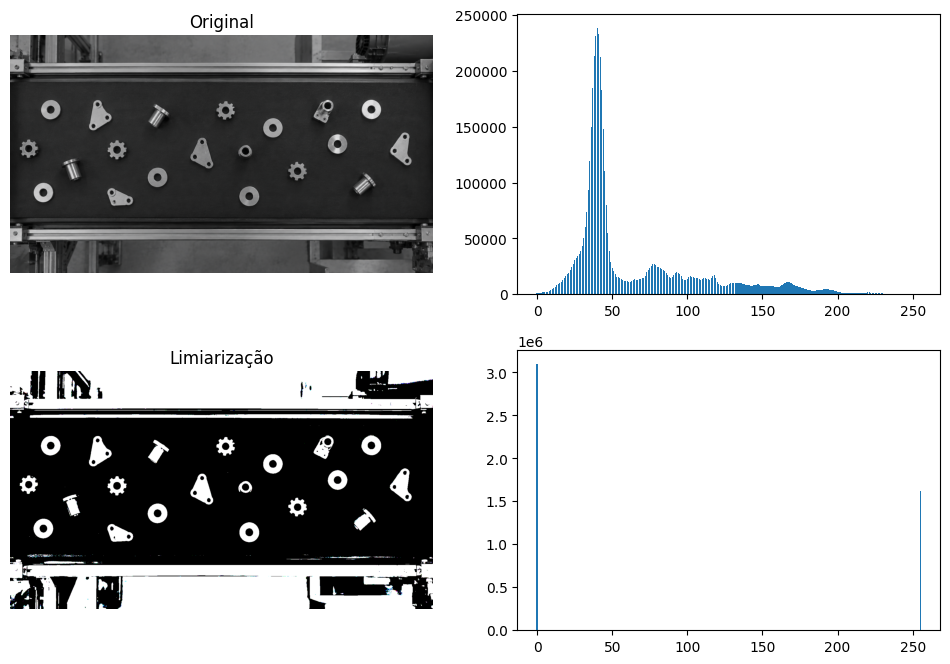

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_4, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].bar(range(256), img_4_array)

axes[1, 0].imshow(img_4_limiarizada, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Limiarização")
axes[1, 0].axis('off')

axes[1, 1].bar(range(256), img_4_limiarizada_array)

plt.savefig('imagem_4_limiarizada.png', bbox_inches='tight', dpi=300)
plt.show()

# Imagem 5

In [44]:
def negativo(imagem):
    return 255 - imagem

In [45]:
img_5_negativo = negativo(img_5)

img_5_negativo_vetor = img_5_negativo.ravel()

img_5_negativo_array = np.zeros(256)
for pixel in img_5_negativo_vetor:
  img_5_negativo_array[pixel] += 1

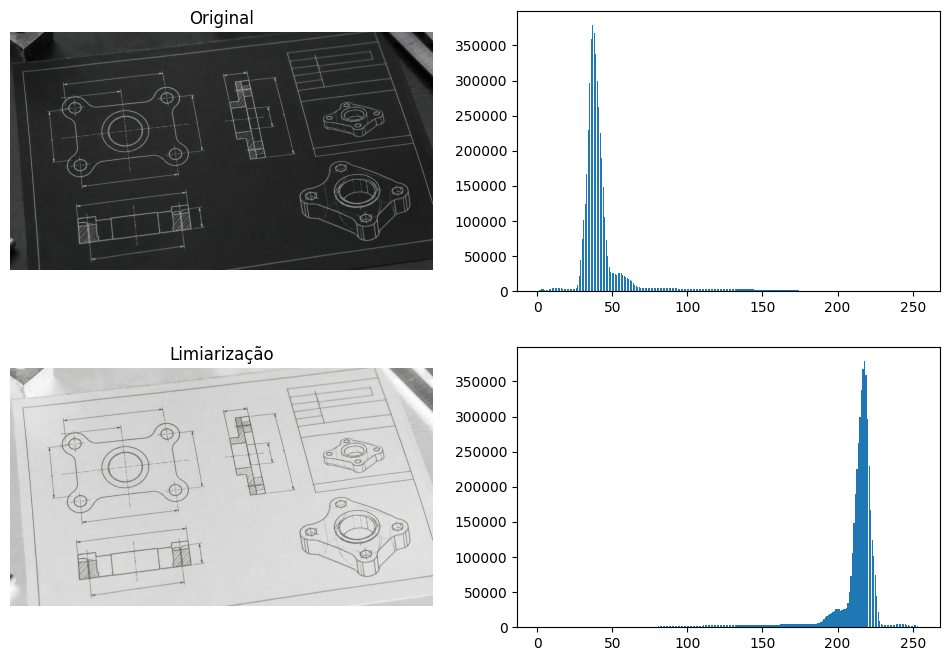

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_5, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].bar(range(256), img_5_array)

axes[1, 0].imshow(img_5_negativo, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title("Limiarização")
axes[1, 0].axis('off')

axes[1, 1].bar(range(256), img_5_negativo_array)

plt.savefig('imagem_5_negativo.png', bbox_inches='tight', dpi=300)
plt.show()